### Explore Bike Share Data

This project uses R to explore 900,000 sampled bike-share trips from Chicago, New York City, and Washington during January-June 2017. Four questions are answered with numeric summaries, labeled visualizations, and written interpretations.


### Data Import and Preparation

The function below imports and prepares one city at a time. `Map` applies it to all three files, reducing repetitive code. The filename check supports both common spellings of the New York file.


In [1]:
# Return the first available filename so the notebook works with either version.
first_existing <- function(candidates) {
  found <- candidates[file.exists(candidates)]
  if (length(found) == 0) stop("A required dataset file is missing.")
  found[1]
}

# Import and standardize the fields used in the analysis.
read_city <- function(path, city_name) {
  d <- read.csv(path, stringsAsFactors = FALSE, check.names = FALSE)
  core <- c("Start Time", "End Time", "Trip Duration", "Start Station",
            "End Station", "User Type")
  if (!all(core %in% names(d))) stop(paste("Required columns missing from", path))
  d <- d[, core]
  d$City <- city_name
  d$StartDateTime <- as.POSIXct(d[["Start Time"]], format = "%Y-%m-%d %H:%M:%S", tz = "UTC")
  d$Month <- format(d$StartDateTime, "%B")
  d$Weekday <- factor(weekdays(d$StartDateTime),
                      levels = c("Monday", "Tuesday", "Wednesday", "Thursday",
                                 "Friday", "Saturday", "Sunday"), ordered = TRUE)
  d$Hour <- as.integer(format(d$StartDateTime, "%H"))
  d[["Trip Duration"]] <- as.numeric(d[["Trip Duration"]])
  d$UserTypeClean <- ifelse(is.na(d[["User Type"]]) | d[["User Type"]] == "",
                            "Missing", d[["User Type"]])
  d[!is.na(d$StartDateTime) & !is.na(d[["Trip Duration"]]), ]
}

files <- c(first_existing(c("chicago.csv")),
           first_existing(c("new-york-city.csv", "new_york_city.csv")),
           first_existing(c("washington.csv")))
cities <- c("Chicago", "New York City", "Washington")

# Map is a loop that applies the same function to each file/city pair.
city_data <- Map(read_city, files, cities)
bikes <- do.call(rbind, city_data)
row.names(bikes) <- NULL

# Quality checks stop execution if the import is incomplete.
stopifnot(nrow(bikes) == 900000)
stopifnot(length(unique(bikes$City)) == 3)
table(bikes$City)



       Chicago New York City    Washington 
        300000        300000        300000


### Question 1

**Which month, weekday, and hour are most popular for starting trips in each city?**

This question identifies the most frequent travel periods. The table supplies numeric counts and the line chart shows the full hourly pattern.


             City Most common month Trips Most common day Trips Most common hour Trips
          Chicago              June 98081         Tuesday 45912               17 35992
    New York City              June 76022       Wednesday 52087               17 30041
       Washington              June 68339       Wednesday 48156                8 33019


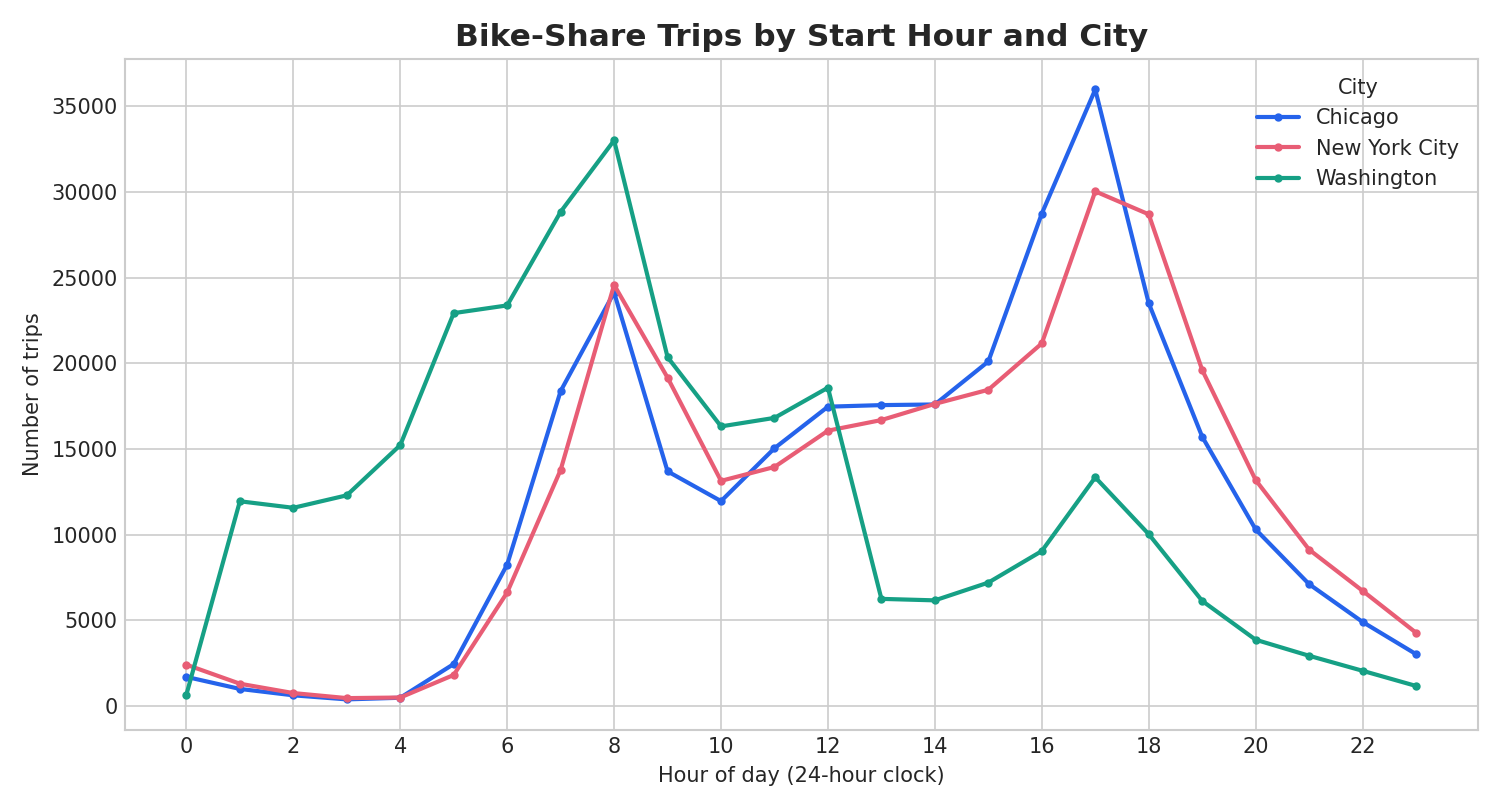

In [2]:
# Helper returns the most frequent value and its count.
mode_and_count <- function(x) {
  counts <- table(x, useNA = "no")
  winner <- which.max(counts)
  c(Value = names(counts)[winner], Trips = as.integer(counts[winner]))
}

popular_times <- do.call(rbind, lapply(split(bikes, bikes$City), function(d) {
  month <- mode_and_count(d$Month)
  day <- mode_and_count(d$Weekday)
  hour <- mode_and_count(d$Hour)
  data.frame(City = d$City[1], MostCommonMonth = month["Value"], MonthTrips = month["Trips"],
             MostCommonDay = day["Value"], DayTrips = day["Trips"],
             MostCommonHour = hour["Value"], HourTrips = hour["Trips"], row.names = NULL)
}))
print(popular_times, row.names = FALSE)

hourly <- as.data.frame(table(City = bikes$City, Hour = bikes$Hour))
hourly$Hour <- as.integer(as.character(hourly$Hour))
plot(NULL, xlim = c(0,23), ylim = range(hourly$Freq),
     main = "Bike-Share Trips by Start Hour and City",
     xlab = "Hour of day (24-hour clock)", ylab = "Number of trips")
plot_colors <- c("#2563EB", "#E85D75", "#16A085")
for (i in seq_along(cities)) {
  z <- hourly[hourly$City == cities[i], ]
  lines(z$Hour, z$Freq, type = "o", col = plot_colors[i], lwd = 2, pch = 16)
}
legend("topleft", legend = cities, col = plot_colors, lty = 1, pch = 16,
       title = "City", bty = "n")


**Summary of Question 1.** June is the most common month in all three cities. Chicago and New York City have their largest hourly demand at 17:00, while Washington peaks at 08:00. The strong morning and evening patterns suggest substantial commuter use; bike rebalancing should occur before each city's larger peak.


### Question 2

**How do total and typical trip durations differ among the three cities?**

Total, mean, and median duration are reported. The median is important because unusually long rides can raise the mean.


             City  Trips Total hours Mean minutes Median minutes
          Chicago 300000    78019.94        15.60          11.17
    New York City 300000    74973.68        14.99          10.15
       Washington 300000   103106.66        20.62          11.78


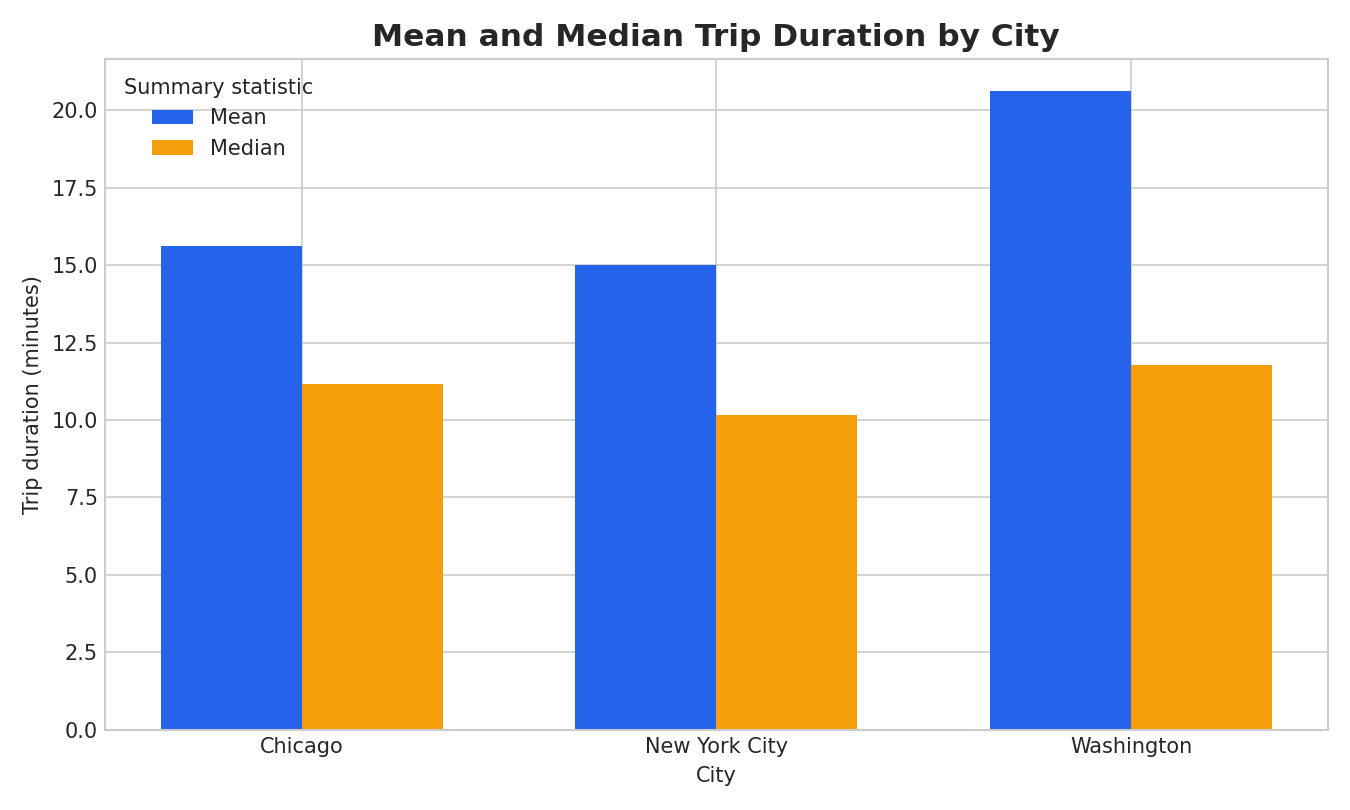

In [3]:
duration_summary <- do.call(rbind, lapply(split(bikes, bikes$City), function(d) {
  seconds <- d[["Trip Duration"]]
  data.frame(City = d$City[1], Trips = length(seconds),
             TotalHours = sum(seconds) / 3600,
             MeanMinutes = mean(seconds) / 60,
             MedianMinutes = median(seconds) / 60)
}))
print(duration_summary, row.names = FALSE, digits = 2)

duration_matrix <- t(as.matrix(duration_summary[, c("MeanMinutes", "MedianMinutes")]))
colnames(duration_matrix) <- duration_summary$City
barplot(duration_matrix, beside = TRUE, col = c("#2563EB", "#F59E0B"),
        main = "Mean and Median Trip Duration by City", xlab = "City",
        ylab = "Trip duration (minutes)", legend.text = c("Mean", "Median"),
        args.legend = list(title = "Summary statistic", bty = "n"))


**Summary of Question 2.** Washington has the longest mean (20.62 minutes) and median (11.78 minutes). In every city, the mean exceeds the median, indicating right-skewed trip durations. Therefore, the median better represents a typical ride, while total hours describe overall system use.


### Question 3

**How does user-type composition differ by city?**

Counts and percentages are calculated from all 300,000 records per city. Missing New York values are retained as a separate category rather than silently removed.


             City   User Type  Trips Percent
          Chicago    Customer  61110  20.37%
          Chicago   Dependent      1   0.00%
          Chicago  Subscriber 238889  79.63%
    New York City    Customer  30159  10.05%
    New York City     Missing    692   0.23%
    New York City  Subscriber 269149  89.72%
       Washington    Customer  79214  26.40%
       Washington  Subscriber 220786  73.60%


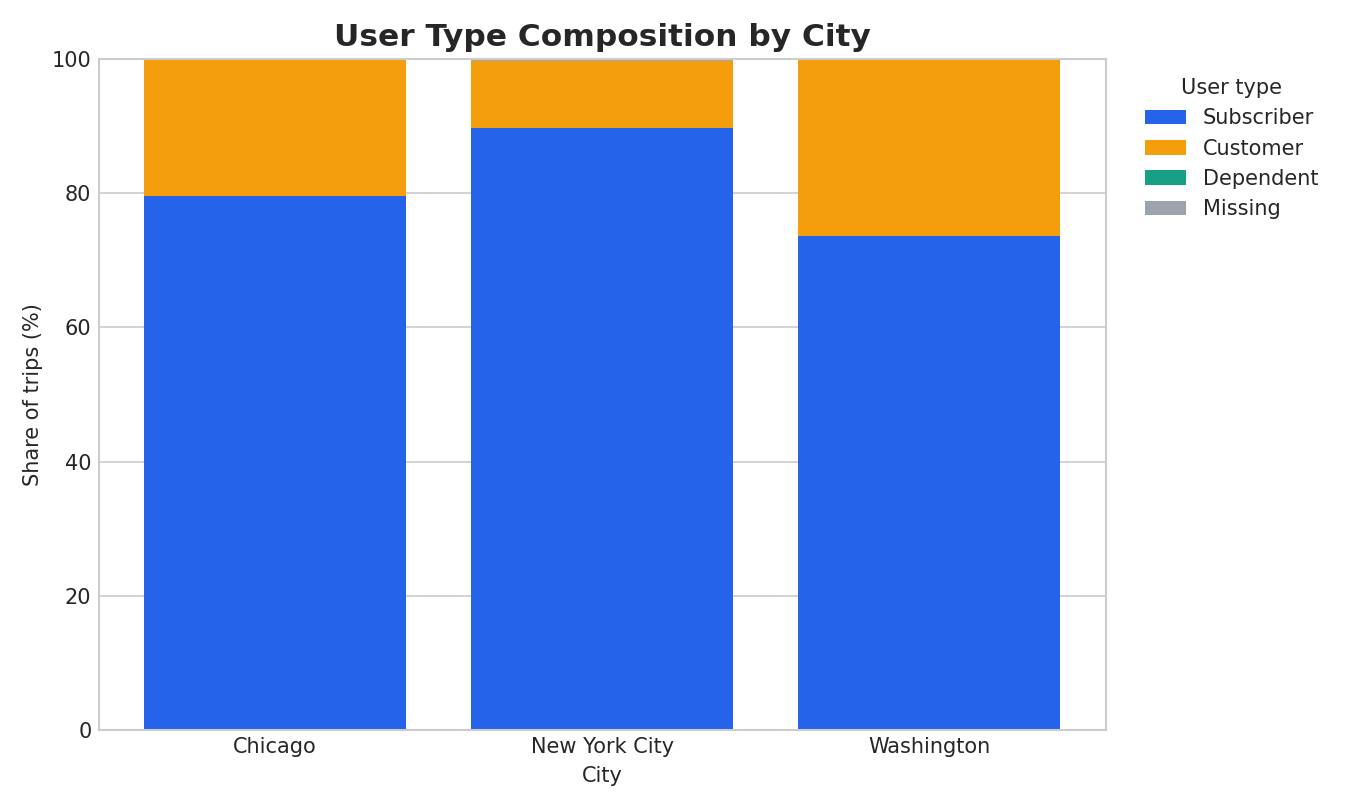

In [4]:
user_counts <- as.data.frame(table(City = bikes$City, UserType = bikes$UserTypeClean))
user_counts <- user_counts[user_counts$Freq > 0, ]
names(user_counts)[3] <- "Trips"
city_totals <- aggregate(Trips ~ City, user_counts, sum)
user_summary <- merge(user_counts, city_totals, by = "City", suffixes = c("", "Total"))
user_summary$Percent <- 100 * user_summary$Trips / user_summary$TripsTotal
print(user_summary[, c("City", "UserType", "Trips", "Percent")], row.names = FALSE, digits = 4)

user_matrix <- prop.table(table(bikes$UserTypeClean, bikes$City), margin = 2) * 100
barplot(user_matrix, col = c("#F59E0B", "#16A085", "#9CA3AF", "#2563EB"),
        main = "User Type Composition by City", xlab = "City",
        ylab = "Share of trips (%)", ylim = c(0,100),
        legend.text = rownames(user_matrix),
        args.legend = list(title = "User type", x = "topright", bty = "n"))


**Summary of Question 3.** Subscribers are the majority in Chicago (79.63%), New York City (89.72%), and Washington (73.60%). Washington has the largest customer share (26.40%), suggesting comparatively stronger casual or visitor use. New York contains 692 missing user-type values (0.23%), which are disclosed in the analysis.


### Question 4

**How is demand distributed across weekdays in each city?**

The chart uses each weekday's percentage of its city total, allowing a fair comparison among cities.


             City Peak weekday Trips Percent
          Chicago      Tuesday 45912  15.30%
    New York City    Wednesday 52087  17.36%
       Washington    Wednesday 48156  16.05%


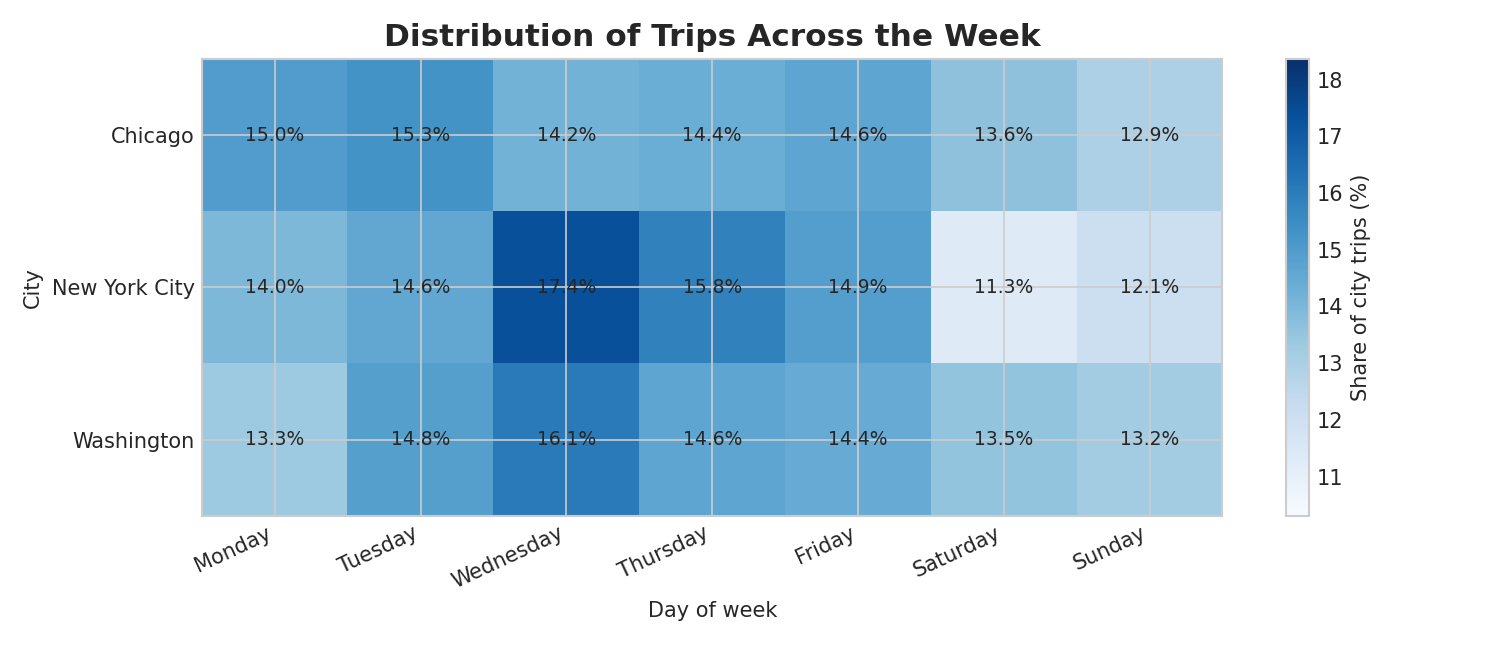

In [5]:
weekday_counts <- as.data.frame(table(City = bikes$City, Weekday = bikes$Weekday))
names(weekday_counts)[3] <- "Trips"
weekday_counts$Percent <- ave(weekday_counts$Trips, weekday_counts$City,
                              FUN = function(x) 100 * x / sum(x))
weekday_peaks <- do.call(rbind, lapply(split(weekday_counts, weekday_counts$City),
                                      function(d) d[which.max(d$Trips), ]))
print(weekday_peaks, row.names = FALSE, digits = 4)

weekday_matrix <- prop.table(table(bikes$City, bikes$Weekday), margin = 1) * 100
image(t(weekday_matrix[nrow(weekday_matrix):1, ]), axes = FALSE,
      col = colorRampPalette(c("white", "#2563EB"))(20),
      main = "Distribution of Trips Across the Week",
      xlab = "Day of week", ylab = "City")
axis(1, at = seq(0,1,length.out = 7), labels = colnames(weekday_matrix))
axis(2, at = seq(0,1,length.out = 3), labels = rev(rownames(weekday_matrix)))


**Summary of Question 4.** Chicago's largest share occurs Tuesday (15.30%). New York City and Washington peak Wednesday (17.36% and 16.05%). This supports the commuter-demand pattern seen in Question 1.


### Conclusions and Limitations

The three systems show strong commuting patterns, but their trip duration and customer composition differ. Operators should rebalance bikes before city-specific peaks, report medians alongside means, and consider Washington's larger casual-customer segment in marketing and station planning.

These datasets are random samples limited to January-June 2017. Washington lacks gender and birth-year fields, and the data contain no weather, station-capacity, or trip-purpose variables. The findings describe patterns but do not establish causation.


## Finishing Up

Before submission, use **Kernel > Restart & Run All** and confirm that every cell completes without an error. Then export the notebook to HTML using the final code cell.


In [ ]:
# Export this completed notebook to HTML. A return status of 0 means success.
system("jupyter nbconvert --to html Explore_bikeshare_data.ipynb")
